In [2]:
from utils import get_hdf5_files, get_filename, get_continuous_behaviors, get_discrete_states, get_eigenworms, get_kymograph, get_neuronal_traces

import os
import math
from matplotlib import pyplot as plt
from matplotlib import patches
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.cross_decomposition import CCA
from sklearn.metrics import r2_score
from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold

import jax
import jax.numpy as jnp
import optax

from distinctipy import distinctipy

# GCAMP DATA

In [3]:
path = f'{os.getcwd()}/../data/{os.path.basename(os.getcwd())}/exported_data_/'
hdf5files = get_hdf5_files(path)
filenames = [get_filename(file) for file in hdf5files]
continuous_behaviors = [get_continuous_behaviors(file) for file in hdf5files]
discrete_states = [get_discrete_states(file) for file in hdf5files]
eigenworms = [get_eigenworms(file) for file in hdf5files]
kymographs = [get_kymograph(file) for file in hdf5files]
traces = [get_neuronal_traces(file) for file in hdf5files]

## preprocessing

In [4]:
for i in range(len(filenames)):
	mask = eigenworms[i].notna().all(axis=1)
	#continuous_behaviors[i] = continuous_behaviors[i][mask]
	discrete_states[i] = discrete_states[i][mask]
	eigenworms[i] = eigenworms[i][mask]
	traces[i] = traces[i][mask]

	#kymographs[i] = kymographs[i][mask]
	#filenames[i] = filenames[i][mask]

# HGM

In [13]:
lambda_1, lambda_2 = 1, 1

random_key = jax.random.PRNGKey(0)
optimizer = optax.adam(1e-2)


def init_params_hgm(shape_U, shape_VT, shape_X, shape_X_man):
    return {
        'U': 1E-2 * jax.random.normal(random_key, shape_U),
        'VT': 1E-2 * jax.random.normal(random_key, shape_VT),
        'W1': 1E-2 * jax.random.normal(random_key, shape_X),
        'W2': 1E-2 * jax.random.normal(random_key, shape_X_man)
    }

def predict_hgm(X, B_ll, params):
	U, W1, W2 = params['U'], params['W1'], params['W2']
	X_man = X @ U
	Y_pred = B_ll @ W1 * jax.nn.sigmoid(X_man @ W2)
	return Y_pred

def loss_fn_hgm(params, X, B_ll, B_hl):
	U, VT, W1, W2 = params['U'], params['VT'], params['W1'], params['W2']

	X_man = X @ U

	B_hl_pred = X_man @ VT
	man_loss = jnp.mean((B_hl_pred - B_hl) ** 2)

	Y_pred = B_ll @ W1 * jax.nn.sigmoid(X_man @ W2)

	X_rec = X_man @ jax.numpy.linalg.pinv(U)
	X_res = X - X_rec
	hgm_loss = jnp.mean((Y_pred - X_res) ** 2)

	return lambda_1 * man_loss + lambda_2 * hgm_loss

@jax.jit
def update_hgm(opt_state, params, X, B_ll, B_hl):
    grads = jax.grad(loss_fn_hgm)(params, X, B_ll, B_hl)
    params_updates, opt_state = optimizer.update(grads, opt_state, params)
    params_new = optax.apply_updates(params, params_updates)
    return params_new, opt_state

34/34: ZIM2165_Gcamp7b_worm1-2022_11_28_no_image_data 


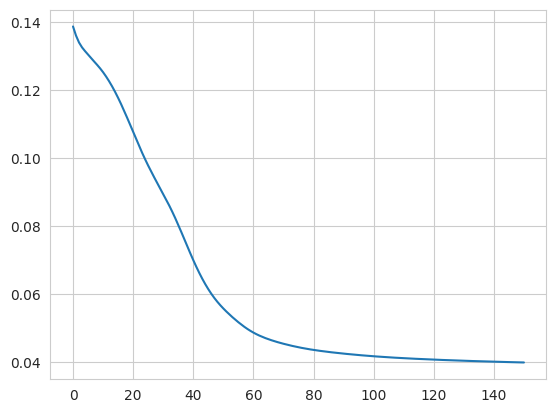

In [14]:
i = 33
print(f'{i+1}/{len(filenames)}: {filenames[i]} ')

X = traces[i].values
B_hl = discrete_states[i].values
B_ll = eigenworms[i].values

n_neurons = X.shape[1]
n_dimensions = 2
n_behaviors_hl = B_hl.shape[1]
n_behaviors_ll = B_ll.shape[1]

params = init_params_hgm((n_neurons, n_dimensions), (n_dimensions, n_behaviors_hl), (n_behaviors_ll, n_neurons), (n_dimensions, n_neurons))
opt_state = optimizer.init(params)

losses = [loss_fn_hgm(params, X, B_ll, B_hl).item()]
for epoch in range(150):
	params, opt_state = update_hgm(opt_state, params, X, B_ll, B_hl)
	loss = loss_fn_hgm(params, X, B_ll, B_hl).item()
	losses.append(loss)

plt.plot(losses)

# GLM

In [18]:
lambda_1, lambda_2 = 1, 1

random_key = jax.random.PRNGKey(0)
optimizer = optax.adam(1e-2)


def init_params_glm(shape_U, shape_VT, shape_X):
    return {
        'U': 1E-2 * jax.random.normal(random_key, shape_U),
        'VT': 1E-2 * jax.random.normal(random_key, shape_VT),
        'W1': 1E-2 * jax.random.normal(random_key, shape_X)
    }

def predict_glm(B_ll, params):
	U, W1 = params['U'], params['W1']
	Y_pred = B_ll @ W1
	return Y_pred

def loss_fn_glm(params, X, B_ll):
	U, VT, W1 = params['U'], params['VT'], params['W1']

	Y_pred = B_ll @ W1

	X_man = X @ U
	X_rec = X_man @ jax.numpy.linalg.pinv(U)
	X_res = X - X_rec
	glm_loss = jnp.mean((Y_pred - X_res) ** 2)

	return lambda_2 * glm_loss

@jax.jit
def update_glm(opt_state, params, X, B_ll):
    grads = jax.grad(loss_fn_glm)(params, X, B_ll)
    params_updates, opt_state = optimizer.update(grads, opt_state, params)
    params_new = optax.apply_updates(params, params_updates)
    return params_new, opt_state

34/34: ZIM2165_Gcamp7b_worm1-2022_11_28_no_image_data 


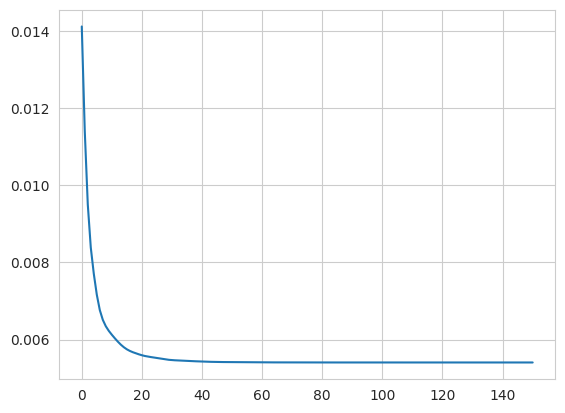

In [19]:
i = 33
print(f'{i+1}/{len(filenames)}: {filenames[i]} ')

X = traces[i].values
B_hl = discrete_states[i].values
B_ll = eigenworms[i].values

n_neurons = X.shape[1]
n_dimensions = 2
n_behaviors_hl = B_hl.shape[1]
n_behaviors_ll = B_ll.shape[1]

params = init_params_glm((n_neurons, n_dimensions), (n_dimensions, n_behaviors_hl), (n_behaviors_ll, n_neurons))
opt_state = optimizer.init(params)

losses = [loss_fn_glm(params, X, B_ll).item()]
for epoch in range(150):
	params, opt_state = update_glm(opt_state, params, X, B_ll)
	loss = loss_fn_glm(params, X, B_ll).item()
	losses.append(loss)

plt.plot(losses)